# FRASCI paper benchmarks

This is the paper-facing molecular notebook for *Fragment-based Selected Configuration Interaction*.
It replaces the separate small-molecule, large-system, Expanded-Parent, and Fe$_4$S$_4$ COO notebooks.

The notebook has two modes:

- `RECOMPUTE = False` (default) reads the compact frozen manifest and regenerates every table and graph below in seconds.
- `RECOMPUTE = True` runs the released Parent and fixed-frame Recovery code from the distributed FCIDUMPs and writes runtime state under `notebooks/runs/` (ignored by Git). The largest calculations take hours; Fe$_4$S$_4$ is not a laptop smoke test.

The calculation functions are in this notebook rather than hidden in external driver scripts. Frozen records are used only to make the default execution practical and deterministic.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CWD = Path.cwd().resolve()
RELEASE_ROOT = next(
    candidate for candidate in (CWD, CWD.parent)
    if (candidate / "pyproject.toml").is_file()
    and (candidate / "frasci" / "__init__.py").is_file())

DATA_ROOT = RELEASE_ROOT / "notebooks" / "data"
RUN_ROOT = RELEASE_ROOT / "notebooks" / "runs" / "paper_benchmarks"
PAPER_RESULTS = DATA_ROOT / "paper_results.json"

RECOMPUTE = False
SYSTEMS_TO_RUN = ()  # e.g. ("c2h6n4_paper",); use tuple(SYSTEMS) for all six

paper = json.loads(PAPER_RESULTS.read_text())
print(f"Release root: {RELEASE_ROOT}")
print(f"Mode: {'electronic-structure recomputation' if RECOMPUTE else 'frozen paper records'}")

Release root: /Users/abhimuvva/Documents/Masters_Projs/Proj_Flow/LASSCF_TRIMCI_COO/release/FRASCI
Mode: frozen paper records


## Physical systems and production settings

Every partition, fragment electron count, spin multiplicity, Parent setting, and Recovery schedule used by the released molecular campaign is explicit below. Changing a partition requires changing the electron/spin specification with it.

In [2]:
COMMON_PARENT = dict(
    orbopt=True, orbopt_cycles=5, phase0_dets=100, phase1_dets=1000,
    discovery_num_runs=16, refine_num_runs=1, rng_seed=0,
)

SYSTEMS = {
    "c2h6n4_paper": dict(
        label="Tetrazene", orbital_lists=[[0, 3, 4, 7], [1, 2, 5, 6]],
        nelec_per_frag=[(2, 2), (2, 2)], spin_sub=[1, 1],
        parent_kwargs=dict(threshold=1e-5, max_cycle_macro=20, **COMMON_PARENT),
        recovery_targets=(2, 5, 10, 20, 200, 800, 2000, 4800), run_lassis=True),
    "alfe2_11o10e": dict(
        label="AlFe2 (11e,10o)", orbital_lists=[list(range(5)), list(range(5, 10))],
        nelec_per_frag=[(1, 5), (5, 0)], spin_sub=[5, 6],
        parent_kwargs=dict(threshold=1e-5, max_cycle_macro=20, **COMMON_PARENT),
        recovery_targets=(50, 150, 500, 1500, 5000, 15000, 50000), run_lassis=True),
    "bisdiazene": dict(
        label="Bisdiazene", orbital_lists=[[0, 3, 6, 9], [1, 8], [2, 4, 5, 7]],
        nelec_per_frag=[(2, 2), (1, 1), (2, 2)], spin_sub=[1, 1, 1],
        parent_kwargs=dict(threshold=1e-5, max_cycle_macro=40, **COMMON_PARENT),
        recovery_targets=(10, 1000, 5000, 10000, 20000, 63000), run_lassis=True),
    "alfe2_11o20e": dict(
        label="AlFe2 (11e,20o)", orbital_lists=[list(range(10)), list(range(10, 20))],
        nelec_per_frag=[(1, 5), (5, 0)], spin_sub=[5, 6],
        parent_kwargs=dict(threshold=1e-5, max_cycle_macro=20, **COMMON_PARENT),
        recovery_targets=(1000, 4000, 12000, 50000, 150000, 300000, 500000, 750000, 1000000),
        run_lassis=False),
    "fes_dimer_3minus": dict(
        label="FeS dimer(3-)", orbital_lists=[list(range(10)), list(range(10, 20))],
        nelec_per_frag=[(5, 1), (0, 5)], spin_sub=[5, 6],
        parent_kwargs=dict(threshold=1e-5, max_cycle_macro=20, **COMMON_PARENT),
        recovery_targets=(1000, 4000, 12000, 50000, 150000, 300000, 500000), run_lassis=True),
    "fe4s4": dict(
        label="Fe4S4",
        orbital_lists=[[2, 3, 4, 6, 7, 8, 9, 10, 11, 21, 24, 25, 26, 27, 28, 29, 32, 33],
                       [0, 1, 5, 12, 13, 14, 15, 16, 17, 18, 19, 20, 22, 23, 30, 31, 34, 35]],
        nelec_per_frag=[(10, 10), (17, 17)], spin_sub=[1, 1],
        parent_kwargs=dict(
            threshold=1e-4, max_cycle_macro=100, orbopt=True, orbopt_cycles=3,
            phase0_dets=64, phase1_dets=1000, growth_factor_phase1=1.1,
            discovery_num_runs=3, refine_num_runs=1, adaptive_phase_policy=True,
            max_cycle_rdmjk=30, rng_seed=0, n_cpu_workers=2),
        recovery_targets=(5000, 20000, 60000, 150000, 300000, 500000, 750000, 1000000),
        run_lassis=False),
}

for system_id, spec in SYSTEMS.items():
    spec["fcidump"] = DATA_ROOT / system_id / "FCIDUMP"

pd.DataFrame({k: {
    "label": v["label"], "fragments": [len(x) for x in v["orbital_lists"]],
    "electrons": v["nelec_per_frag"], "targets": v["recovery_targets"],
} for k, v in SYSTEMS.items()}).T

                            label  ...                                            targets
c2h6n4_paper            Tetrazene  ...               (2, 5, 10, 20, 200, 800, 2000, 4800)
alfe2_11o10e      AlFe2 (11e,10o)  ...           (50, 150, 500, 1500, 5000, 15000, 50000)
bisdiazene             Bisdiazene  ...              (10, 1000, 5000, 10000, 20000, 63000)
alfe2_11o20e      AlFe2 (11e,20o)  ...  (1000, 4000, 12000, 50000, 150000, 300000, 500...
fes_dimer_3minus    FeS dimer(3-)  ...  (1000, 4000, 12000, 50000, 150000, 300000, 500...
fe4s4                       Fe4S4  ...  (5000, 20000, 60000, 150000, 300000, 500000, 7...

[6 rows x 4 columns]

## From-scratch campaign code

This cell is the runnable calculation path. It imports FRASCI only when a recomputation is requested, builds or reuses a Parent under `notebooks/runs/`, runs the corrected A-prime Recovery ladder, and optionally runs the same-Parent LASSIS adapter where that comparison is valid and tractable.

The accepted AlFe2 `(11e,20o)` LASSIS comparator in the paper comes from the converged paper-auto calculation, not the released phased-Parent adapter; Fe4S4 cannot be bridged to dense fragment CI arrays at this partition. Those two LASSIS values are therefore not recomputed here.

In [3]:
def run_campaign(system_id: str) -> dict:
    from frasci import FCIDUMPInput
    from frasci.parent import ParentConfig, build_lassis_ready_las, solve as solve_parent
    from frasci.recovery.benchmark_ladder import BenchmarkLadderConfig, run as run_benchmark

    spec = SYSTEMS[system_id]
    system_run = RUN_ROOT / system_id
    parent_dir = system_run / "parent"
    checkpoint_dir = system_run / "recovery_checkpoints"
    metadata_path = parent_dir / "checkpoint_metadata.json"

    if metadata_path.is_file():
        meta = json.loads(metadata_path.read_text())
        accepted = meta.get("converged") or meta.get("convergence_status") == "stationary_plateau"
    else:
        accepted = False

    if not accepted:
        t0 = time.perf_counter()
        parent = solve_parent(
            str(spec["fcidump"]), spec["orbital_lists"], spec["nelec_per_frag"],
            spec["spin_sub"], ParentConfig(**spec["parent_kwargs"]),
            save_dets_to=parent_dir)
        accepted = parent.converged or parent.convergence_status == "stationary_plateau"
        if not accepted:
            raise RuntimeError(f"{system_id}: Parent did not reach an accepted state")
        print(f"{system_id}: Parent completed in {(time.perf_counter()-t0)/3600:.2f} h")

    bundle = FCIDUMPInput.from_file(spec["fcidump"])
    ladder = run_benchmark(
        parent_dir, bundle,
        BenchmarkLadderConfig(
            recovery_targets=spec["recovery_targets"], threshold=1e-6, n_ct_max=2,
            las_seed_dets=100, growth_factor=1.5, max_rounds=40,
            solver_kind="auto", dense_dimension_threshold=5000,
            plateau_threshold_mha=0.01, checkpoint_directory=checkpoint_dir))

    lassis = None
    if spec["run_lassis"]:
        from mrh.my_pyscf.lassi.lassis import LASSIS
        parent = solve_parent(
            str(spec["fcidump"]), spec["orbital_lists"], spec["nelec_per_frag"],
            spec["spin_sub"], ParentConfig(**spec["parent_kwargs"]))
        las = build_lassis_ready_las(parent, str(spec["fcidump"]))
        e_roots, _ = LASSIS(las).kernel()
        lassis = {
            "energy_ha": float(np.min(np.atleast_1d(e_roots))),
            "parent_energy_ha": float(parent.e_tot),
        }
        lassis["variational_vs_parent"] = lassis["energy_ha"] <= lassis["parent_energy_ha"] + 1e-6

    return {"system": system_id, "ladder": ladder, "lassis": lassis}


recomputed = {}
if RECOMPUTE:
    if not SYSTEMS_TO_RUN:
        raise ValueError("Set SYSTEMS_TO_RUN explicitly before starting expensive calculations")
    RUN_ROOT.mkdir(parents=True, exist_ok=True)
    for system_id in SYSTEMS_TO_RUN:
        recomputed[system_id] = run_campaign(system_id)
        print(system_id, recomputed[system_id]["ladder"]["stop_reason"])
else:
    print("Recomputation skipped. Set RECOMPUTE=True and choose SYSTEMS_TO_RUN to run it.")

Recomputation skipped. Set RECOMPUTE=True and choose SYSTEMS_TO_RUN to run it.


## Accepted molecular endpoints

The table is regenerated from `paper_results.json`. Exact FCI references are used for the three tractable systems, external DMRG values for the two `(11e,20o)` systems, and a same-FCIDUMP whole-system TrimCI+COO variational comparator for Fe4S4. The Fe4S4 post-Recovery COO point is listed separately in the manuscript because it relaxes the fixed-frame condition.

In [4]:
rows = []
for s in paper["systems"]:
    rows.append({
        "system": s["label"].replace("$_2$", "2").replace("$_4$", "4"),
        "Parent (Ha)": s["parent_energy_ha"],
        "LASSIS (Ha)": s["lassis_energy_ha"],
        "FRASCI (Ha)": s["frasci_energy_ha"],
        "reference (Ha)": s["baseline_energy_ha"],
        "FRASCI gap (mHa)": s["frasci_difference_signed_mha"],
        "achieved N": s["selected_n"],
        "endpoint status": s["endpoint_status"],
    })
endpoint_table = pd.DataFrame(rows).set_index("system")
endpoint_table

                 Parent (Ha)  ...                         endpoint status
system                        ...                                        
Tetrazene        -296.879529  ...                          pool exhausted
AlFe2 (11e,10o) -3971.791491  ...                          pool exhausted
Bisdiazene       -295.569433  ...                          pool exhausted
AlFe2 (11e,20o) -3971.890269  ...                          target reached
FeS dimer(3-)   -5068.747825  ...                          target reached
Fe4S4            -327.052659  ...  target reached; schedule not plateaued

[6 rows x 7 columns]

## Endpoint accuracy

Only systems with valid paired LASSIS and fixed-frame FRASCI values appear here. The logarithmic floor makes the stored AlFe2 `(11e,10o)` difference visible without treating it as evidence below exact FCI.

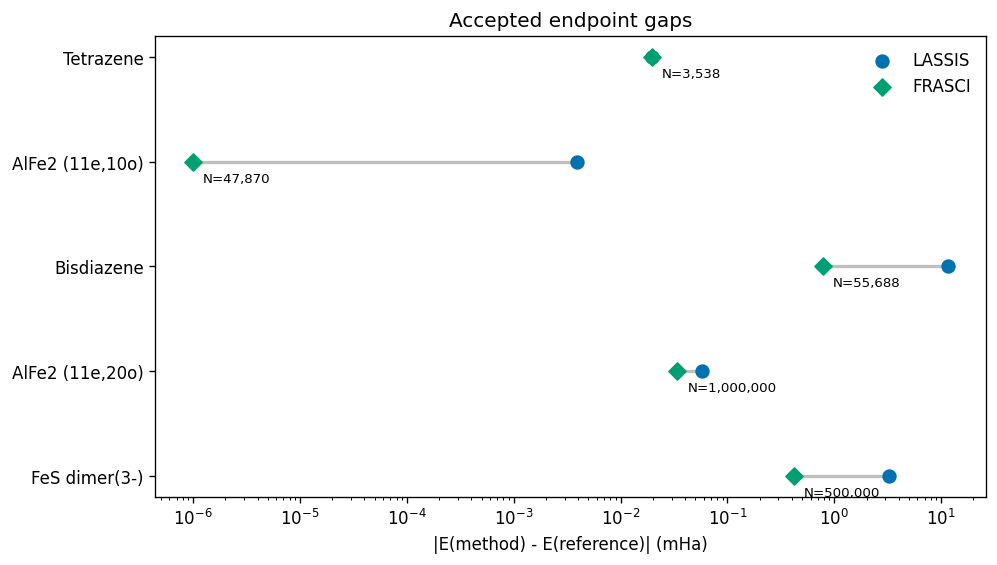

In [5]:
paired = [s for s in paper["systems"] if s["include_in_endpoint_gap_figure"]]
y = np.arange(len(paired))[::-1]
floor = 1e-6
fig, ax = plt.subplots(figsize=(8.2, 4.6), constrained_layout=True)
for yi, s in zip(y, paired):
    lassis_gap = abs(1000.0 * (s["lassis_energy_ha"] - s["baseline_energy_ha"]))
    frasci_gap = max(abs(s["frasci_difference_signed_mha"]), floor)
    ax.plot([frasci_gap, lassis_gap], [yi, yi], color="0.75", lw=2, zorder=1)
    ax.scatter(lassis_gap, yi, color="#0072B2", marker="o", s=58, label="LASSIS" if yi == y[0] else None)
    ax.scatter(frasci_gap, yi, color="#009E73", marker="D", s=52, label="FRASCI" if yi == y[0] else None)
    ax.annotate(f"N={s['selected_n']:,}", (frasci_gap, yi), xytext=(6, -12), textcoords="offset points", fontsize=8)
ax.set_xscale("log")
ax.set_yticks(y, [s["label"].replace("$_2$", "2") for s in paired])
ax.set_xlabel("|E(method) - E(reference)| (mHa)")
ax.set_title("Accepted endpoint gaps")
ax.legend(frameon=False)
plt.show()

## Fixed-frame Recovery ladders

Each curve contains only compatible retained rungs. The horizontal line is the stated reference or comparator, not necessarily an exact energy. A curve ending at the largest requested budget is not labeled converged unless its stored stopping criterion supports that statement.

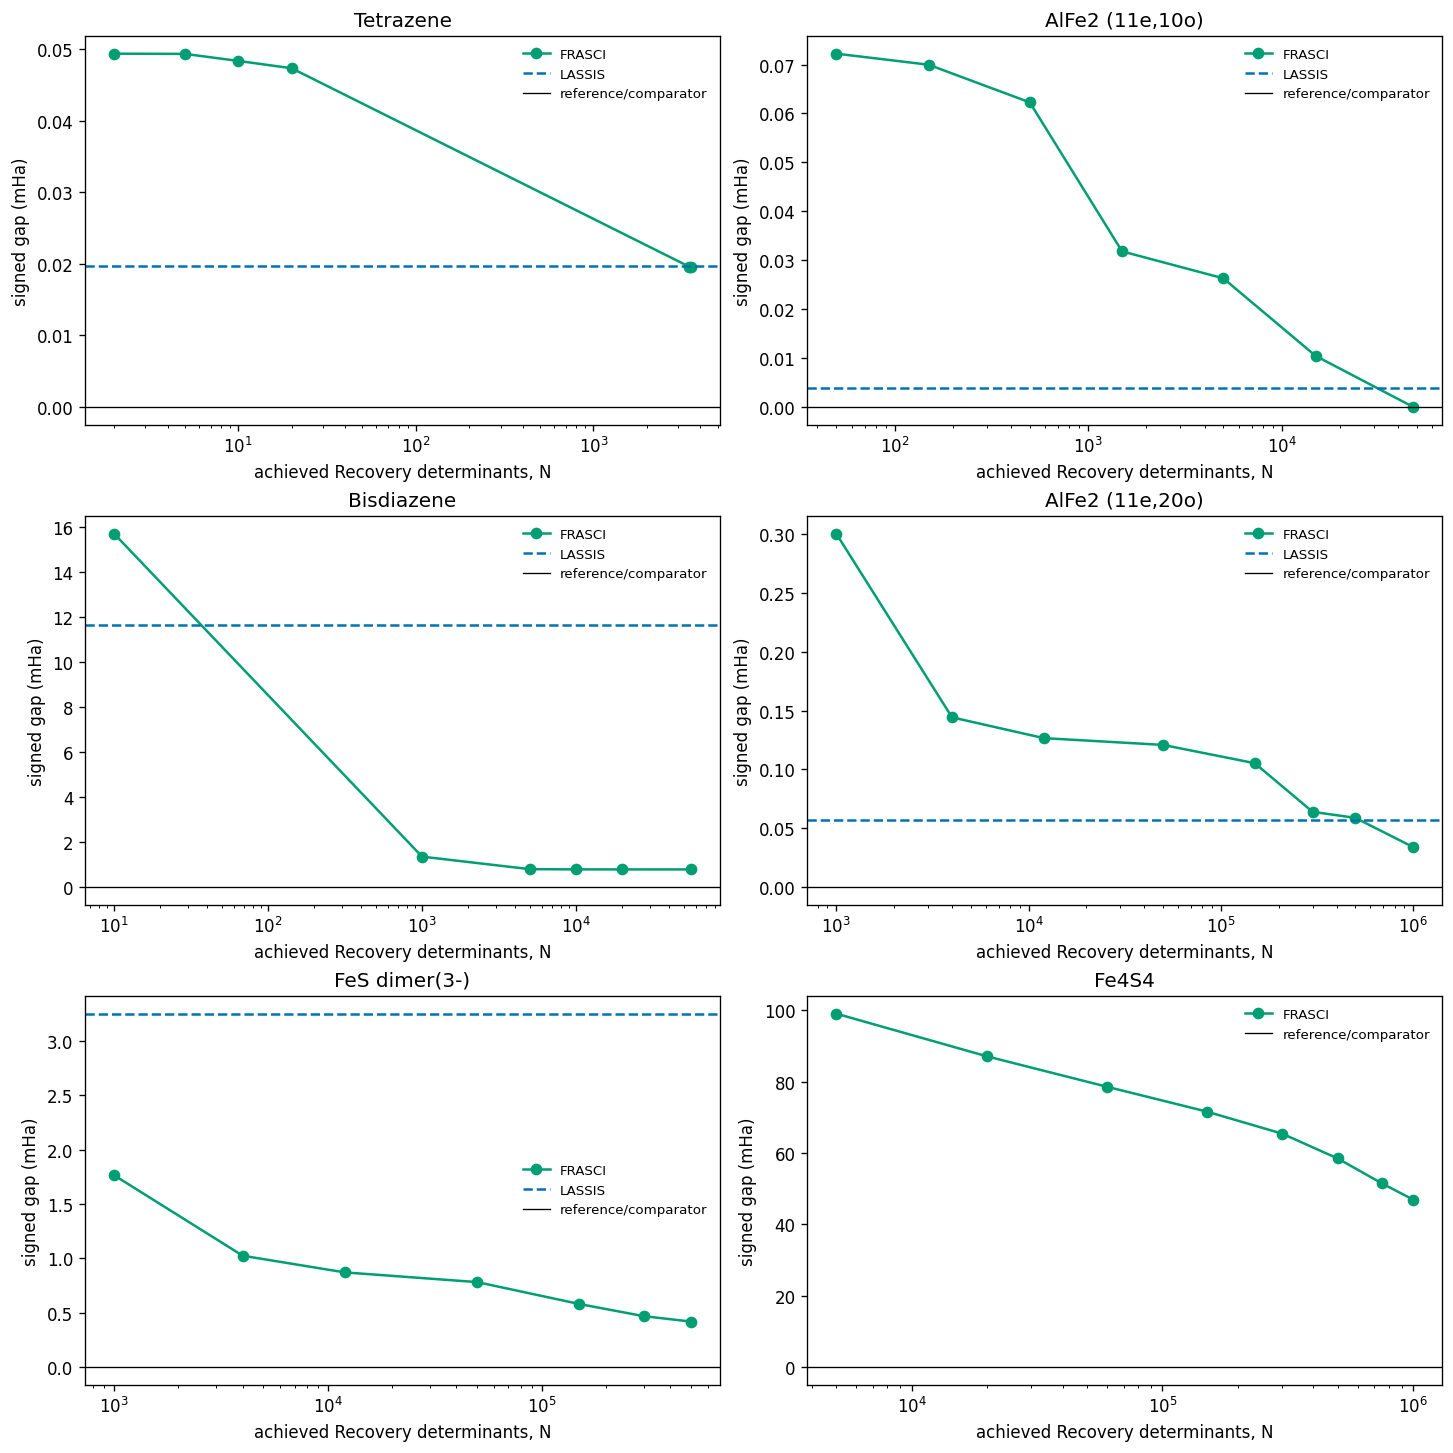

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(12, 12), constrained_layout=True)
for ax, s in zip(axes.flat, paper["systems"]):
    ladder = s["compatible_ladder"]
    n = np.array([r["achieved_n"] for r in ladder])
    e = np.array([r["energy_ha"] for r in ladder])
    ax.plot(n, 1000.0 * (e - s["baseline_energy_ha"]), "o-", color="#009E73", label="FRASCI")
    if s["lassis_energy_ha"] is not None:
        ax.axhline(1000.0 * (s["lassis_energy_ha"] - s["baseline_energy_ha"]), color="#0072B2", ls="--", label="LASSIS")
    ax.axhline(0, color="black", lw=0.8, label="reference/comparator")
    ax.set_xscale("log")
    ax.set_title(s["label"].replace("$_2$", "2").replace("$_4$", "4"))
    ax.set_xlabel("achieved Recovery determinants, N")
    ax.set_ylabel("signed gap (mHa)")
    ax.legend(frameon=False, fontsize=8)
plt.show()

## Expanded-Parent diagnostic

Expanded-Parent reoptimizes the `K` largest determinant products without Recovery or orbital rotation. This diagnostic isolates amplitude factorization in the contracted Parent; it is not the default FRASCI protocol.

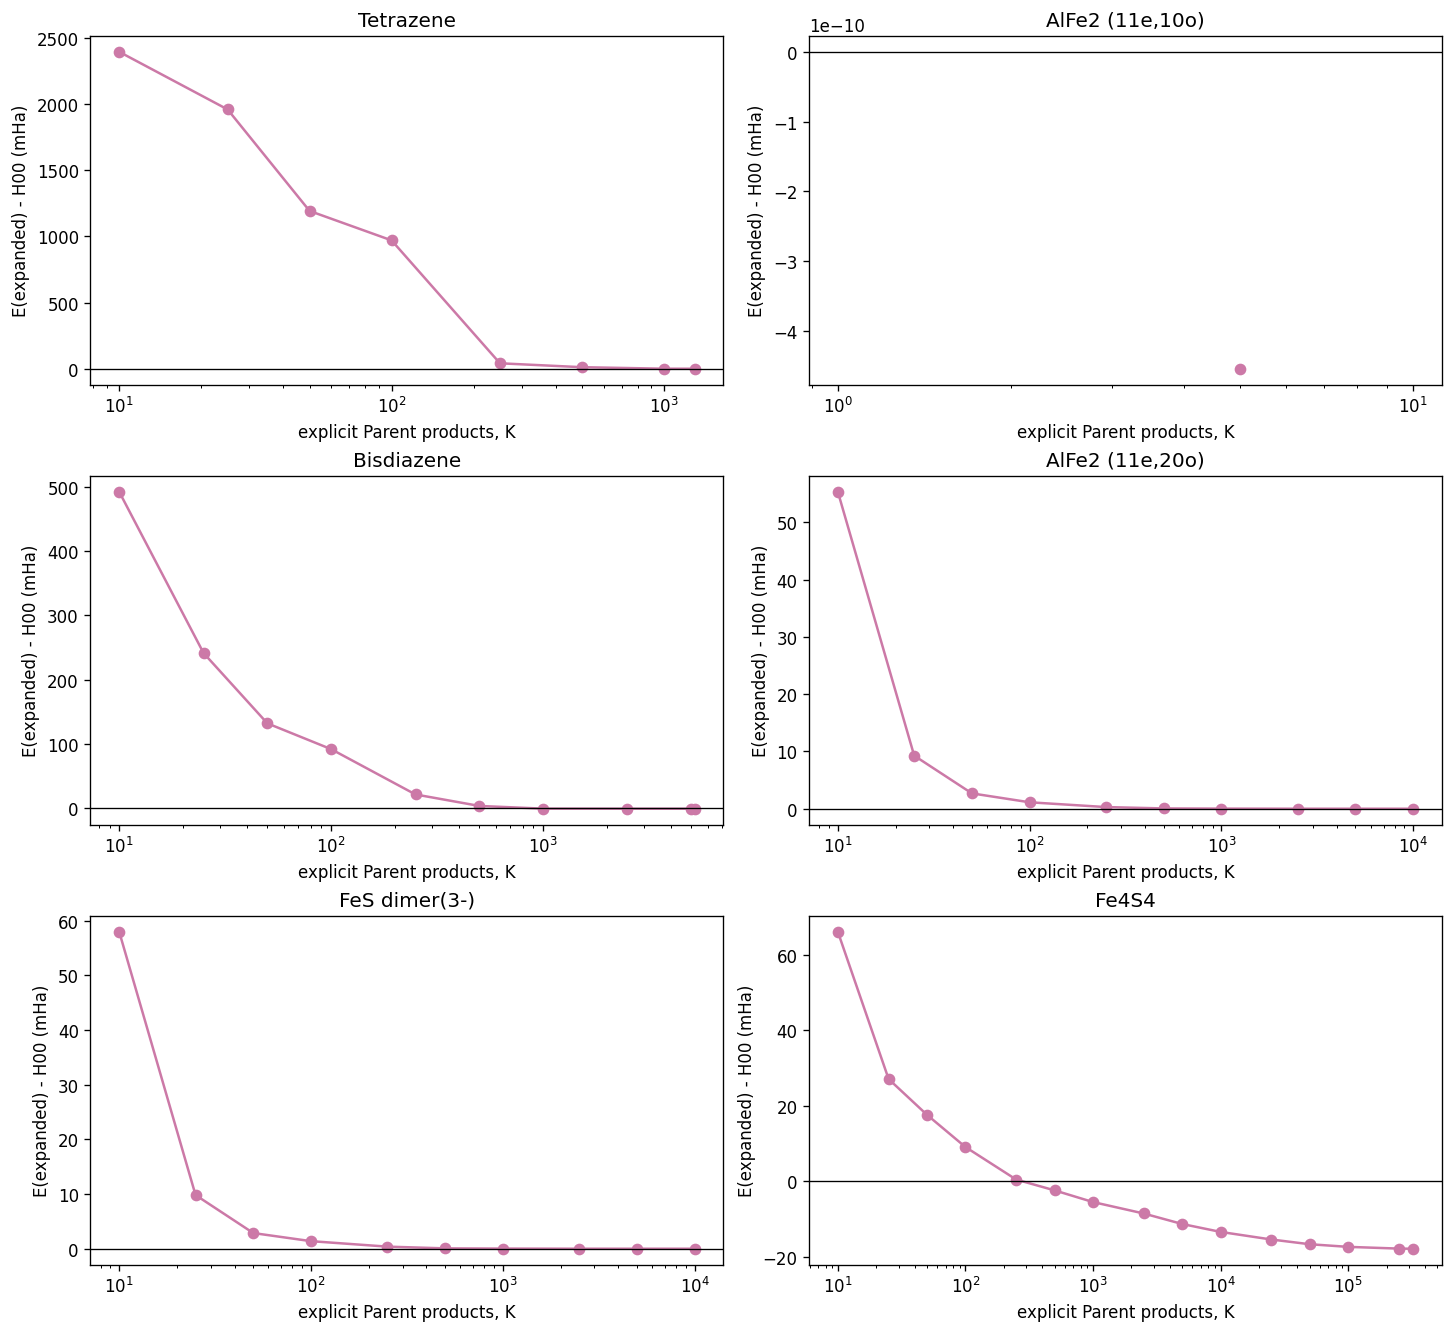

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(12, 11), constrained_layout=True)
for ax, s in zip(axes.flat, paper["systems"]):
    d = paper["expanded_parent"].get(s["system_id"])
    if not d:
        ax.set_visible(False)
        continue
    k = [r["actual_n"] for r in d["rungs"]]
    gap = [r["gap_to_exact_mha"] for r in d["rungs"]]
    ax.plot(k, gap, "o-", color="#CC79A7")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xscale("log")
    ax.set_title(s["label"].replace("$_2$", "2").replace("$_4$", "4"))
    ax.set_xlabel("explicit Parent products, K")
    ax.set_ylabel("E(expanded) - H00 (mHa)")
plt.show()

## Fe4S4 post-Recovery COO

The waterfall separates fixed-frame Recovery, explicit Parent-union rediagonalization, and free orbital rotation. The 1M/100k calculation reached the 150-iteration orbital-optimization ceiling, so its final value is a variational candidate rather than a converged orbital optimum.

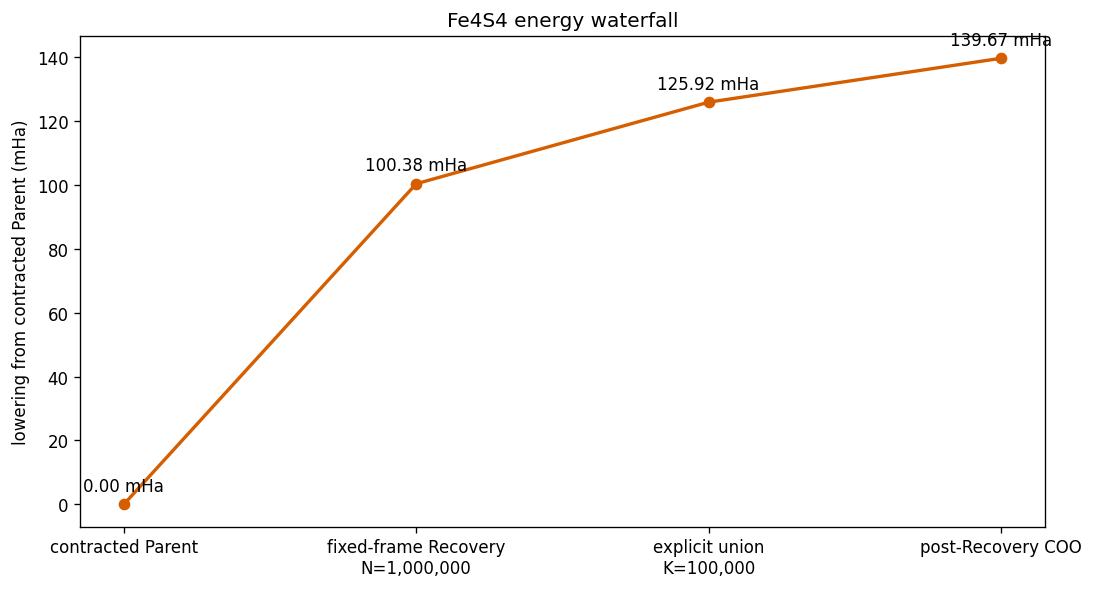

In [8]:
fe4 = next(s for s in paper["systems"] if s["system_id"] == "fe4s4")
coo = max(paper["fe4s4_post_recovery_coo"]["points"], key=lambda p: p["rung"])
stages = [
    ("contracted Parent", fe4["parent_energy_ha"]),
    ("fixed-frame Recovery\nN=1,000,000", fe4["frasci_energy_ha"]),
    ("explicit union\nK=100,000", coo["e_before_ha"]),
    ("post-Recovery COO", coo["e_after_ha"]),
]
labels, energies = zip(*stages)
gains = 1000.0 * (fe4["parent_energy_ha"] - np.array(energies))
fig, ax = plt.subplots(figsize=(9, 4.8), constrained_layout=True)
ax.plot(range(len(stages)), gains, "o-", color="#D55E00", lw=2)
for i, gain in enumerate(gains):
    ax.annotate(f"{gain:.2f} mHa", (i, gain), xytext=(0, 8), textcoords="offset points", ha="center")
ax.set_xticks(range(len(stages)), labels)
ax.set_ylabel("lowering from contracted Parent (mHa)")
ax.set_title("Fe4S4 energy waterfall")
plt.show()

## Reproducibility notes

- Frozen values are data records, not substitutes for the calculation code; the full released recomputation path is above.
- Runtime Parent directories, Recovery reservoirs, and `.npz` checkpoints are intentionally ignored. They can be regenerated from the FCIDUMPs.
- No figure files are written. Every graph is an inline notebook output.
- Random seeds are fixed, but threaded native calculations may not reproduce bitwise-identical search trajectories. Compare certified energies, supports, and gates rather than assuming identical wall times or macroiteration histories.